# Fase 4 — Forecasting baselines e backtesting temporal

**Somente train. Eval congelado. Horizonte fixo de sete dias.**

Quatro folds, 50.000 séries, dois baselines: 2.800.000 previsões. Este notebook consome outputs de `python scripts/run_baseline_backtest.py`. Lógica crítica em src; relatório completo em `docs/forecasting_baselines_report.md`. Não há modelos adicionais ou correção de censura.

ABC, XYZ, exposição e flag são conhecidos em cada origem. O retrato full-train da Fase 3 não é usado nos folds.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'src').is_dir():
    root = root.parent
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
from IPython.display import display
from src.reporting.forecast_plots import load_outputs, PLOTS, save_figure
data = load_outputs(root)
assert data['summary']['source_split'] == 'train'
assert data['summary']['analysis_view'] == 'prospective'
print(f"{data['summary']['n_forecasts']:,} previsões; referência: {data['summary']['reference_baseline']}")

2,800,000 previsões; referência: seasonal_naive


## 01. Desenho dos folds

Origem é o primeiro dia previsto, antes de observar sua venda; cutoff é o dia anterior. Histórico crescente e testes sem sobreposição.

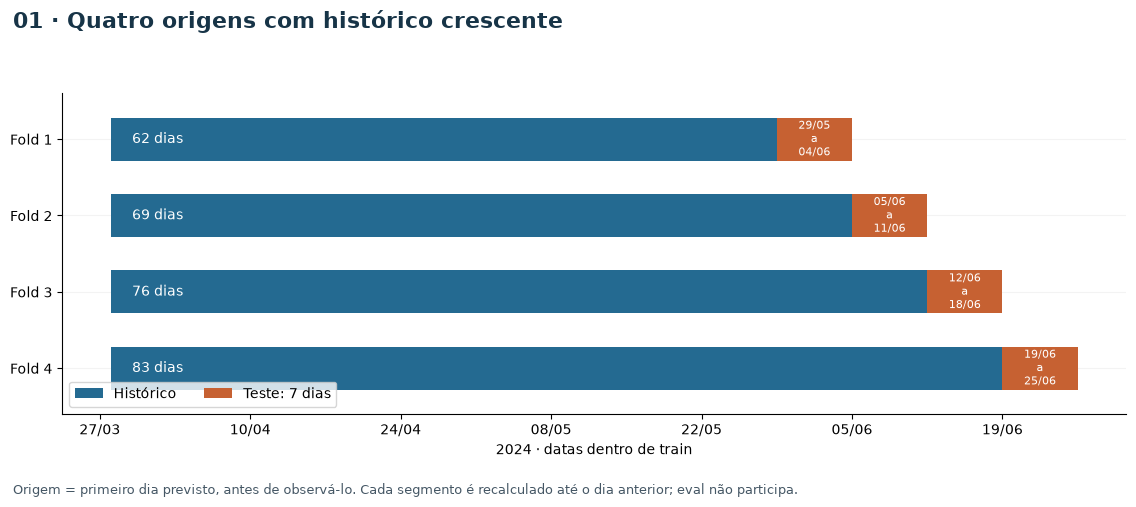

In [2]:
fig = PLOTS[0](data)
save_figure(fig, 1, root)
display(fig)
plt.close(fig)

## 02. WAPE global

Métrica consolidada por somas. Seasonal Naive é referência pelo menor WAPE, com tradeoffs explicitados nas demais figuras.

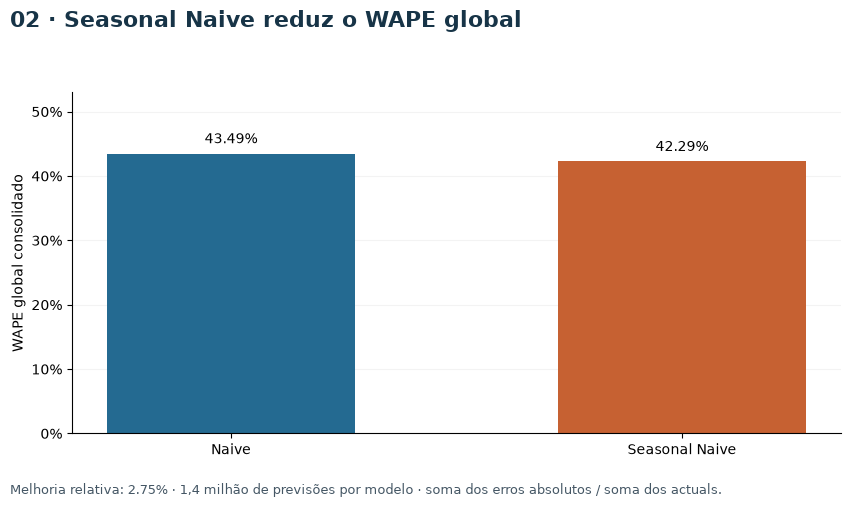

In [3]:
fig = PLOTS[1](data)
save_figure(fig, 2, root)
display(fig)
plt.close(fig)

## 03. MAE e RMSE

Erros na escala da venda observada normalizada. Não são unidades físicas, receita ou demanda latente.

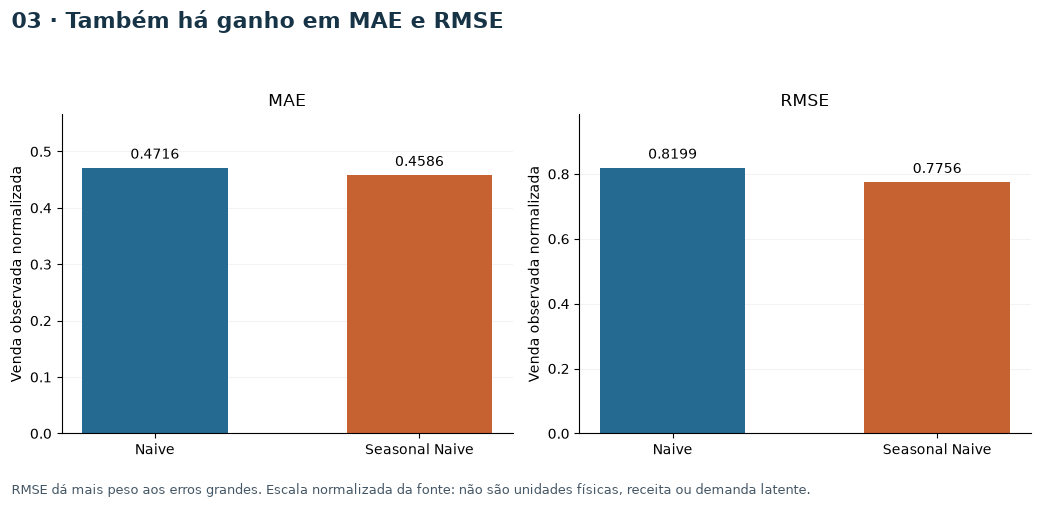

In [4]:
fig = PLOTS[2](data)
save_figure(fig, 3, root)
display(fig)
plt.close(fig)

## 04. Bias por série

Cada série recebe o mesmo peso na distribuição; os 28 dias são agregados antes do bias. Valores negativos representam subprevisão. Escala simétrica log para mostrar todas as caudas.

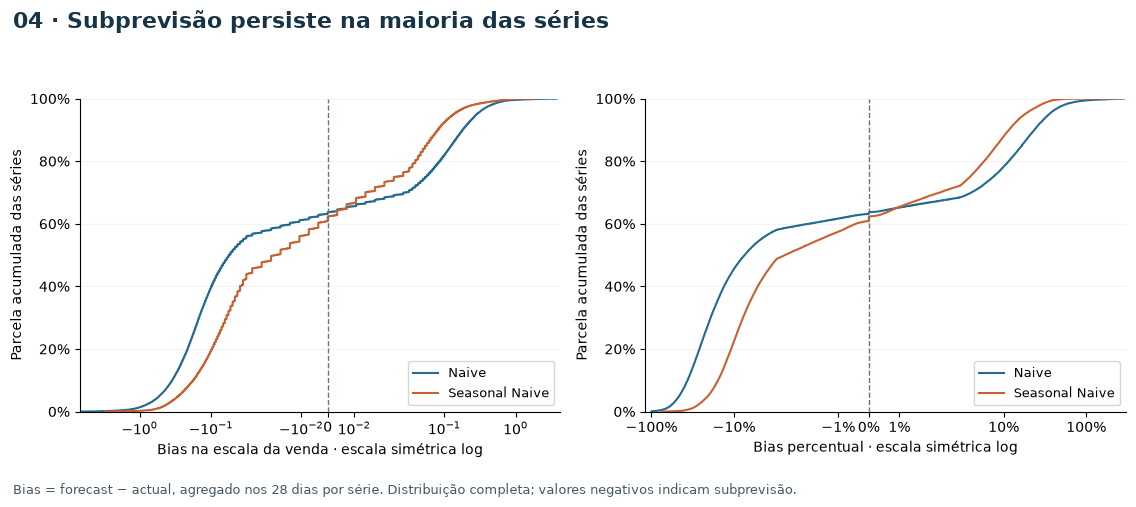

In [5]:
fig = PLOTS[3](data)
save_figure(fig, 4, root)
display(fig)
plt.close(fig)

## 05. Performance XYZ

Classes e quantis recalculados a cada origem. A hipótese de menor erro em X tem apoio parcial, sem ordem universal nem ajuste posterior das regras.

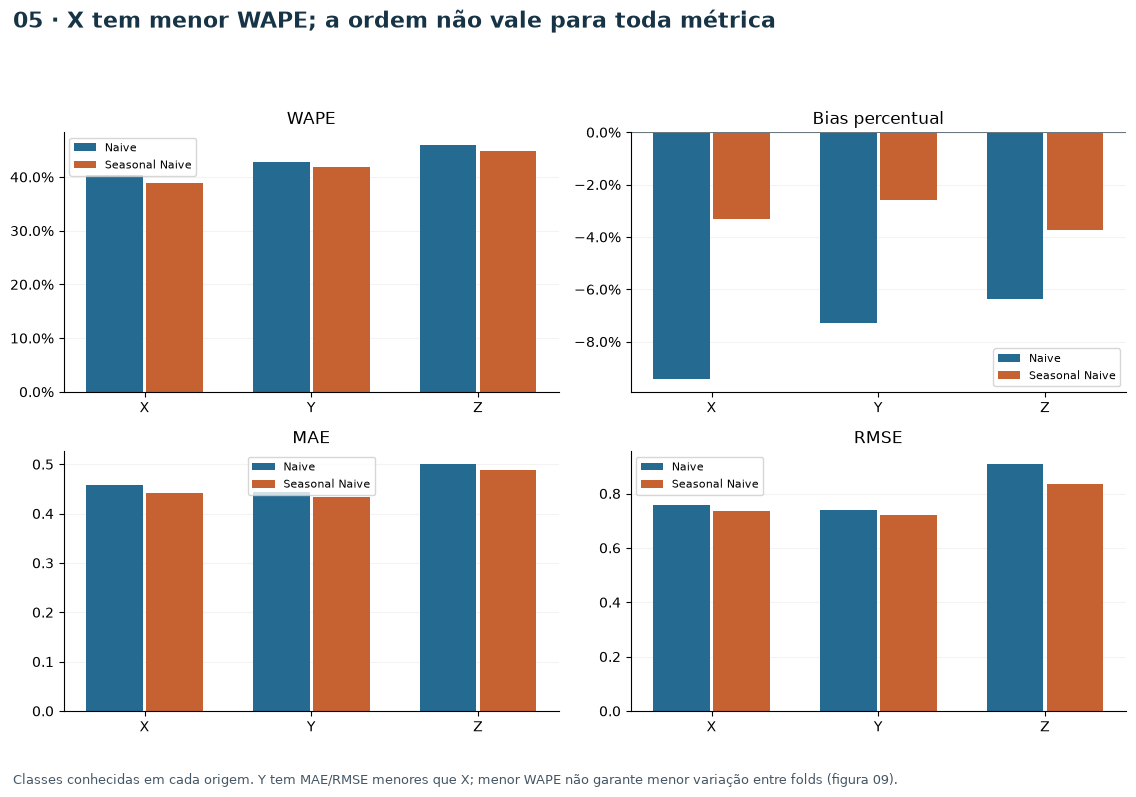

In [6]:
fig = PLOTS[4](data)
save_figure(fig, 5, root)
display(fig)
plt.close(fig)

## 06. Performance ABC

ABC global por produto, propagado para as séries. MAE e WAPE têm leituras distintas por causa da escala.

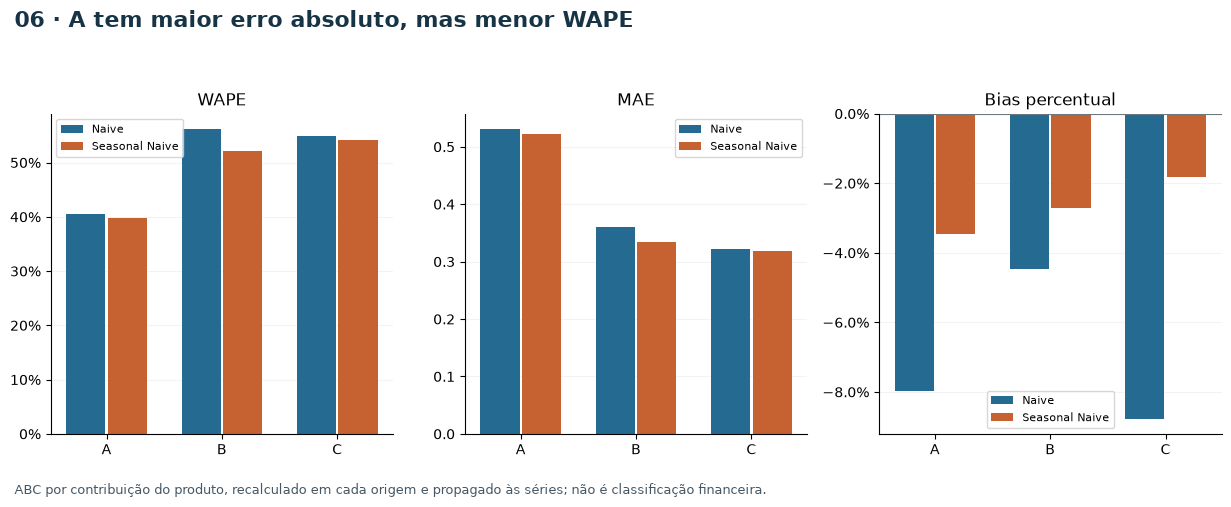

In [7]:
fig = PLOTS[5](data)
save_figure(fig, 6, root)
display(fig)
plt.close(fig)

## 07. Melhoria relativa em ABC × XYZ

Positivo significa ganho do Seasonal Naive. C–Z é uma exceção; não aplicamos melhoria relativa ao bias assinado.

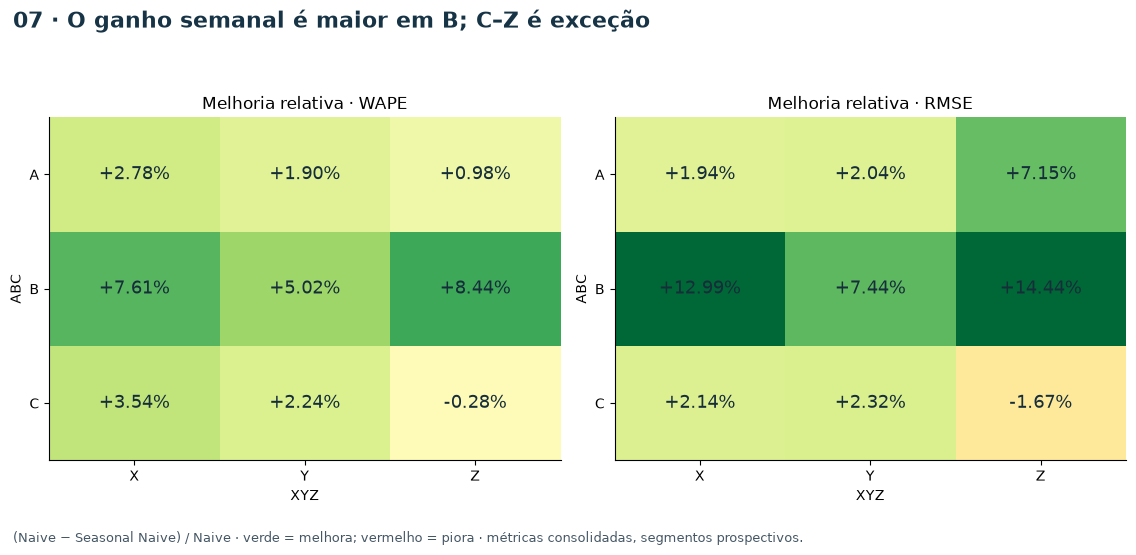

In [8]:
fig = PLOTS[6](data)
save_figure(fig, 7, root)
display(fig)
plt.close(fig)

## 08. Disponibilidade e possível censura

Cortes descritivos, sem inferência causal. A flag piora ligeiramente em MAE/WAPE no Seasonal Naive, mas melhora RMSE e bias.

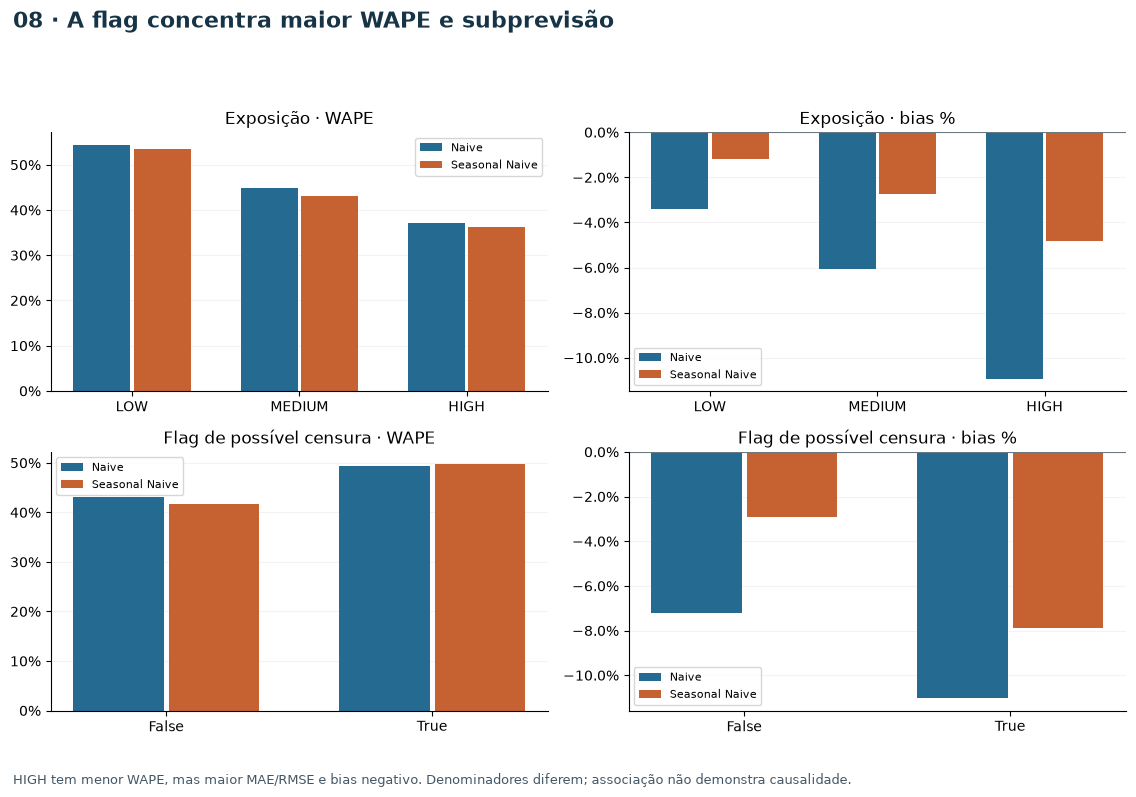

In [9]:
fig = PLOTS[7](data)
save_figure(fig, 8, root)
display(fig)
plt.close(fig)

## 09. Estabilidade temporal

Desvio amostral entre quatro folds; não é intervalo de confiança. Z é mais estável em WAPE no Seasonal Naive, apesar do nível de erro maior.

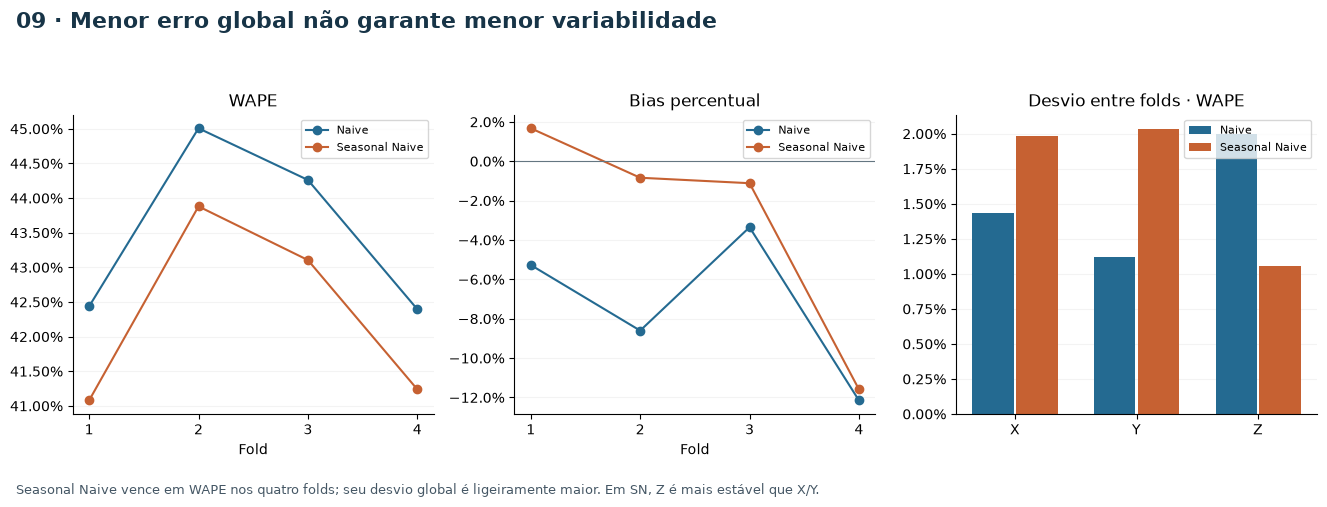

In [10]:
fig = PLOTS[8](data)
save_figure(fig, 9, root)
display(fig)
plt.close(fig)

## 10. Exemplos por regras

Seleção no último fold, com desempate por loja/produto. Melhor/pior/HIGH usam WAPE; subprevisão/flag usam bias mínimo; Naive supera SN usa maior diferença de WAPE. Extremos não representam a população. Denominadores acompanham os gráficos.

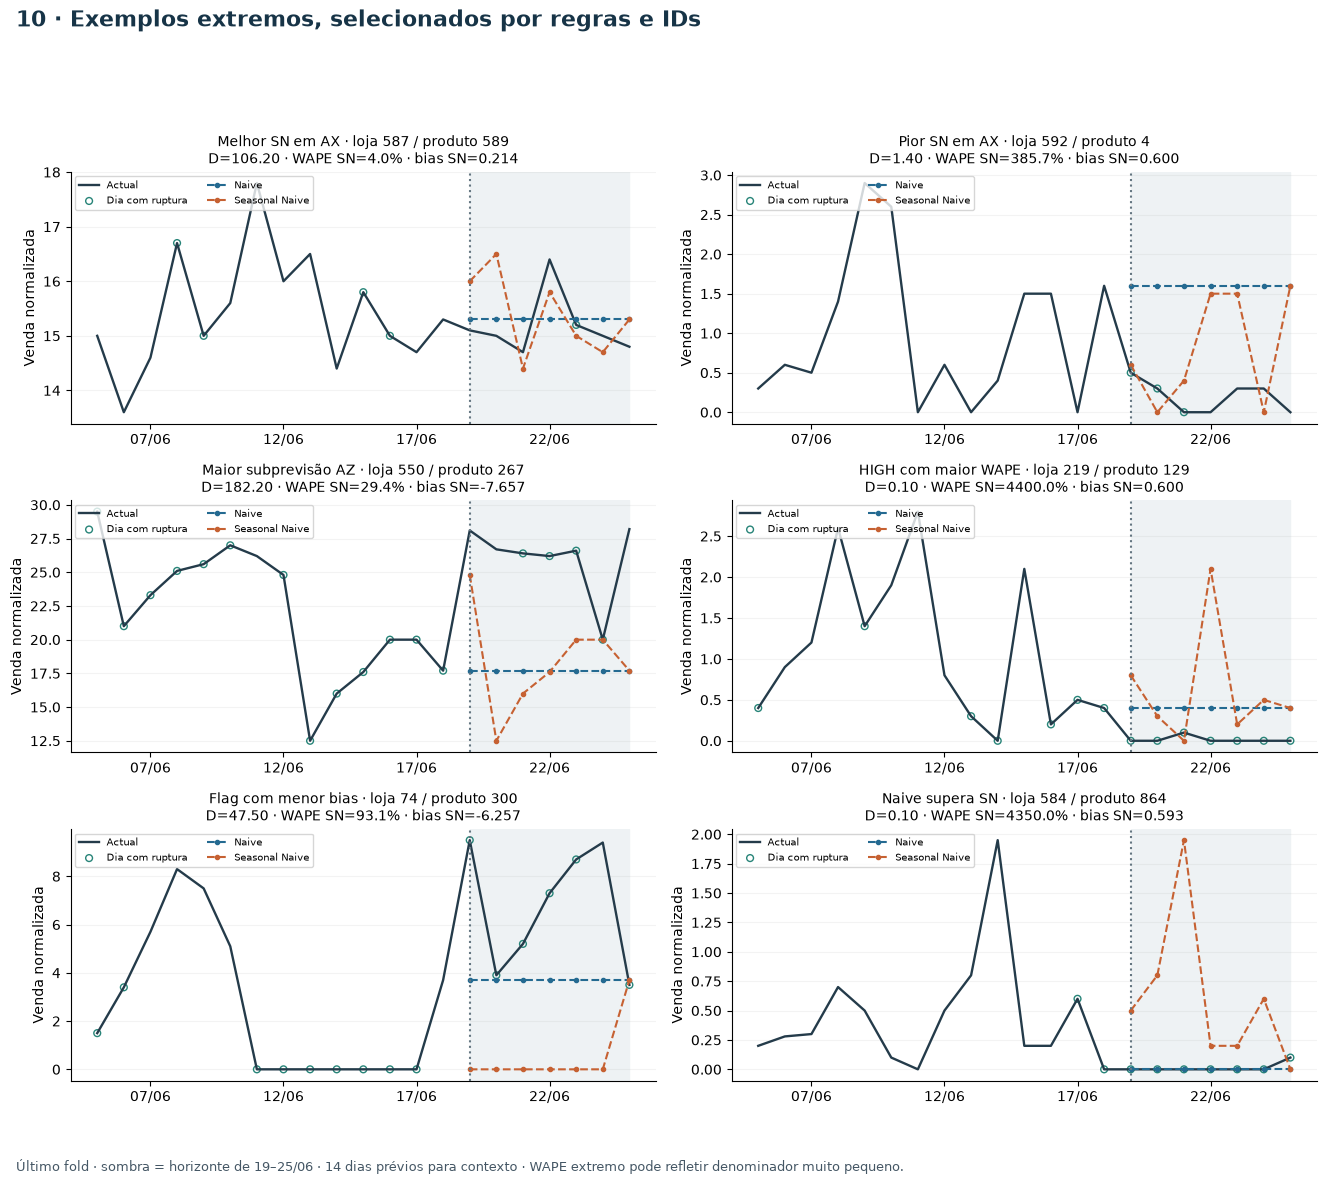

In [11]:
fig = PLOTS[9](data)
save_figure(fig, 10, root)
display(fig)
plt.close(fig)

## Denominadores e conclusão

263 séries×fold por modelo têm soma actual zero: WAPE e bias percentual ficam indefinidos, sem exclusão das métricas absolutas. No agregado dos quatro folds, nenhuma série tem soma zero. Denominadores e p05 de baixa escala constam no relatório e summary.json.

Seasonal Naive reduz o WAPE global em 2,75%, mas perde em C–Z e na flag. A janela curta e os quatro folds limitam generalização; o bias negativo persiste. Manter ambos como referências para uma próxima fase autorizada, sem consultar eval.